
🔥 Test Accuracy: 0.7512

📊 Classification Report:

              precision    recall  f1-score   support

        high       0.80      0.75      0.77      3256
         low       0.61      0.67      0.64      1100
     neutral       0.76      0.78      0.77      2822

    accuracy                           0.75      7178
   macro avg       0.72      0.74      0.73      7178
weighted avg       0.75      0.75      0.75      7178


📌 Confusion Matrix (Numerical Format):
[[2445  274  537]
 [ 204  741  155]
 [ 424  192 2206]]


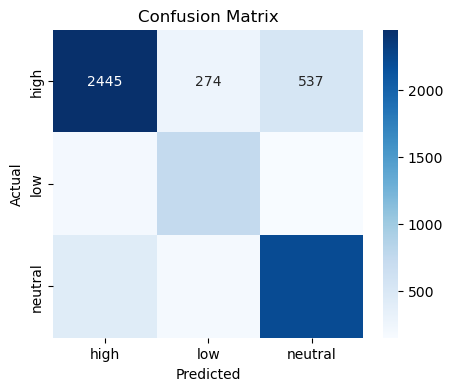

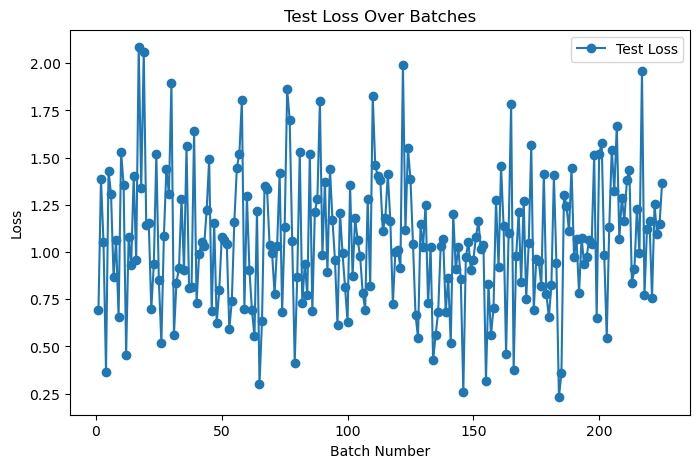

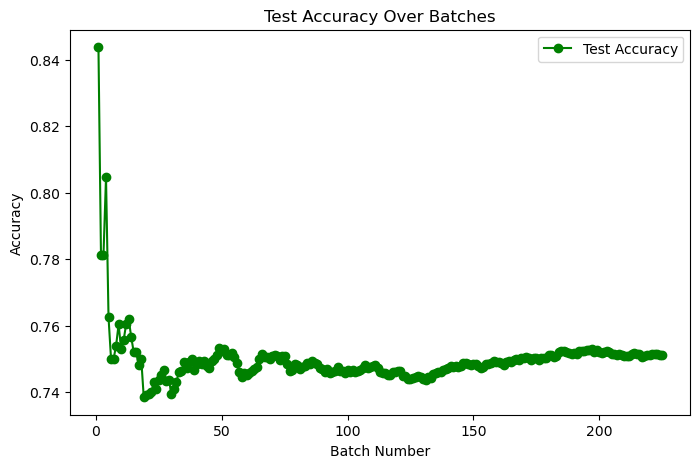

In [1]:
import torch
import timm
import torch.nn as nn
import joblib
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

# Define Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Define Model Class (Same as Used for Training)
class ViTStressDetector(nn.Module):
    def __init__(self, num_classes=3):
        super(ViTStressDetector, self).__init__()
        self.vit = timm.create_model("vit_base_patch16_224", pretrained=False)
        in_features = self.vit.head.in_features
        self.vit.head = nn.Sequential(
            nn.LayerNorm(in_features),
            nn.Dropout(0.3),
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        return self.vit(x)

# Load the trained model
model = ViTStressDetector(num_classes=3).to(device)
model.load_state_dict(torch.load("stress_detection_vit.pth", map_location=device))
model.eval()

# Load Label Encoder
label_encoder = joblib.load("label_encoder.pkl")

# Load and Preprocess FER2013 Dataset
df = pd.read_csv("fer2013.csv")

# Convert pixel strings to numpy arrays and reshape
df['pixels'] = df['pixels'].apply(lambda x: np.array(x.split(), dtype=np.float32).reshape(48, 48))

# Convert grayscale to 3-channel RGB
def to_rgb(image):
    return np.stack([image] * 3, axis=-1)

df['pixels'] = df['pixels'].apply(to_rgb)

# Map emotions to stress levels
stress_mapping = {0: "low", 1: "low", 2: "neutral", 3: "neutral", 4: "high", 5: "high", 6: "high"}
df['emotion'] = df['emotion'].map(stress_mapping)

# Encode labels
df['emotion'] = label_encoder.transform(df['emotion'])

# Split into Test Set (20%)
_, X_test, _, y_test = train_test_split(df['pixels'].values, df['emotion'].values, test_size=0.2, random_state=42, stratify=df['emotion'])

# Define Test Dataset Class
class FERDataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        image = self.images[idx].astype(np.uint8)
        image = Image.fromarray(image)
        if self.transform:
            image = self.transform(image)
        label = torch.tensor(self.labels[idx], dtype=torch.long)
        return image, label

# Define Transformations (Same as Training)
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

# Create Test Dataset & DataLoader
test_dataset = FERDataset(X_test, y_test, transform=transform)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

# Evaluate Model & Store Loss & Accuracy
criterion = nn.CrossEntropyLoss()
all_preds, all_labels = [], []
test_losses, test_accuracies = [], []

correct, total = 0, 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        
        loss = criterion(outputs, labels)
        test_losses.append(loss.item())

        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

        total += labels.size(0)
        correct += (predicted == labels).sum().item()
        test_accuracies.append(correct / total)

# Calculate Final Test Accuracy
final_test_accuracy = accuracy_score(all_labels, all_preds)

# Print Metrics
print(f"\n🔥 Test Accuracy: {final_test_accuracy:.4f}\n")
print("📊 Classification Report:\n")
print(classification_report(all_labels, all_preds, target_names=label_encoder.classes_))

# Compute Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)

# Print Numerical Confusion Matrix
print("\n📌 Confusion Matrix (Numerical Format):")
print(cm)

# Plot Confusion Matrix
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# Plot Test Loss Over Batches
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(test_losses) + 1), test_losses, marker='o', linestyle='-', label="Test Loss")
plt.xlabel("Batch Number")
plt.ylabel("Loss")
plt.title("Test Loss Over Batches")
plt.legend()
plt.show()

# Plot Test Accuracy Over Batches
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(test_accuracies) + 1), test_accuracies, marker='o', linestyle='-', color='green', label="Test Accuracy")
plt.xlabel("Batch Number")
plt.ylabel("Accuracy")
plt.title("Test Accuracy Over Batches")
plt.legend()
plt.show()


In [ ]:
pip install --upgrade optree
